# TUGAS AKHIR: SISTEM KLASIFIKASI GAS MULTI-SENSOR (E-NOSE) BERBASIS MACHINE LEARNING

**Judul Proyek**: Studi Komparasi Algoritma Decision Tree, K-Nearest Neighbors, dan Random Forest dalam Klasifikasi Gas Menggunakan Variasi Sensor MQ (Spesifikasi MQ-2 & Sensor Array)

**Kelompok 4**:
1. REVANZA WILDAN PUTRA WARDANA - 230935605186 (Ketua)
2. MUHAMMAD RAIHAN AMMAR RIFFA'I - 230935607876 (Anggota)
3. RIDA FAIRUZ ZAHIRAH CAESAR - 230532601488 (Anggota)

---
### Fokus Pembaruan Pasca-Presentasi:
1. **Dataset Riil dengan Ground Truth Asli**: Menggunakan data observasi fisik 6.400 baris dengan label kelas asli (`NoGas`, `Smoke`, `Perfume`, `Mixture`) tanpa membuat aturan kelas buatan (if-else).
2. **Fokus Sensor MQ-2 & Variasi Sensor Array**: Membandingkan performa sensor tunggal MQ-2 vs array multi-sensor.
3. **Penambahan Algoritma Random Forest**: Membandingkan Single Decision Tree vs Ensemble Random Forest vs KNN.
4. **Variasi Hyperparameter**: Menganalisis pengaruh parameter (kedalaman pohon, nilai K tetangga, dan jumlah estimator) secara sistematis.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Library Machine Learning & Visualisasi berhasil dimuat.")

Library Machine Learning & Visualisasi berhasil dimuat.


In [2]:
print("=== 1. MEMUAT DATASET SENSOR GAS RIIL (GAS SENSORS MEASUREMENTS) ===")
csv_path = 'Gas_Sensors_Measurements.csv'
df = pd.read_csv(csv_path)

if 'Serial Number' in df.columns:
    df = df.drop(columns=['Serial Number'])

print(f"Dataset berhasil dimuat: {df.shape[0]} baris observasi, {df.shape[1]} kolom.")
print(f"Missing Values: {df.isnull().sum().sum()}")
print("\nDistribusi Kelas Target Riil:")
print(df['Gas'].value_counts())
df.head()

=== 1. MEMUAT DATASET SENSOR GAS RIIL (GAS SENSORS MEASUREMENTS) ===
Dataset berhasil dimuat: 6400 baris observasi, 8 kolom.
Missing Values: 0

Distribusi Kelas Target Riil:
Gas
NoGas      1600
Perfume    1600
Smoke      1600
Mixture    1600
Name: count, dtype: int64


,MQ2,MQ3,MQ5,MQ6,MQ7,MQ8,MQ135,Gas
0,555,515,377,338,666,451,416,NoGas
1,555,516,377,339,666,451,416,NoGas
2,556,517,376,337,666,451,416,NoGas
3,556,516,376,336,665,451,416,NoGas
4,556,516,376,337,665,451,416,NoGas


=== 2. EKSPLORASI DATA & KORELASI ANTAR SENSOR MQ ===


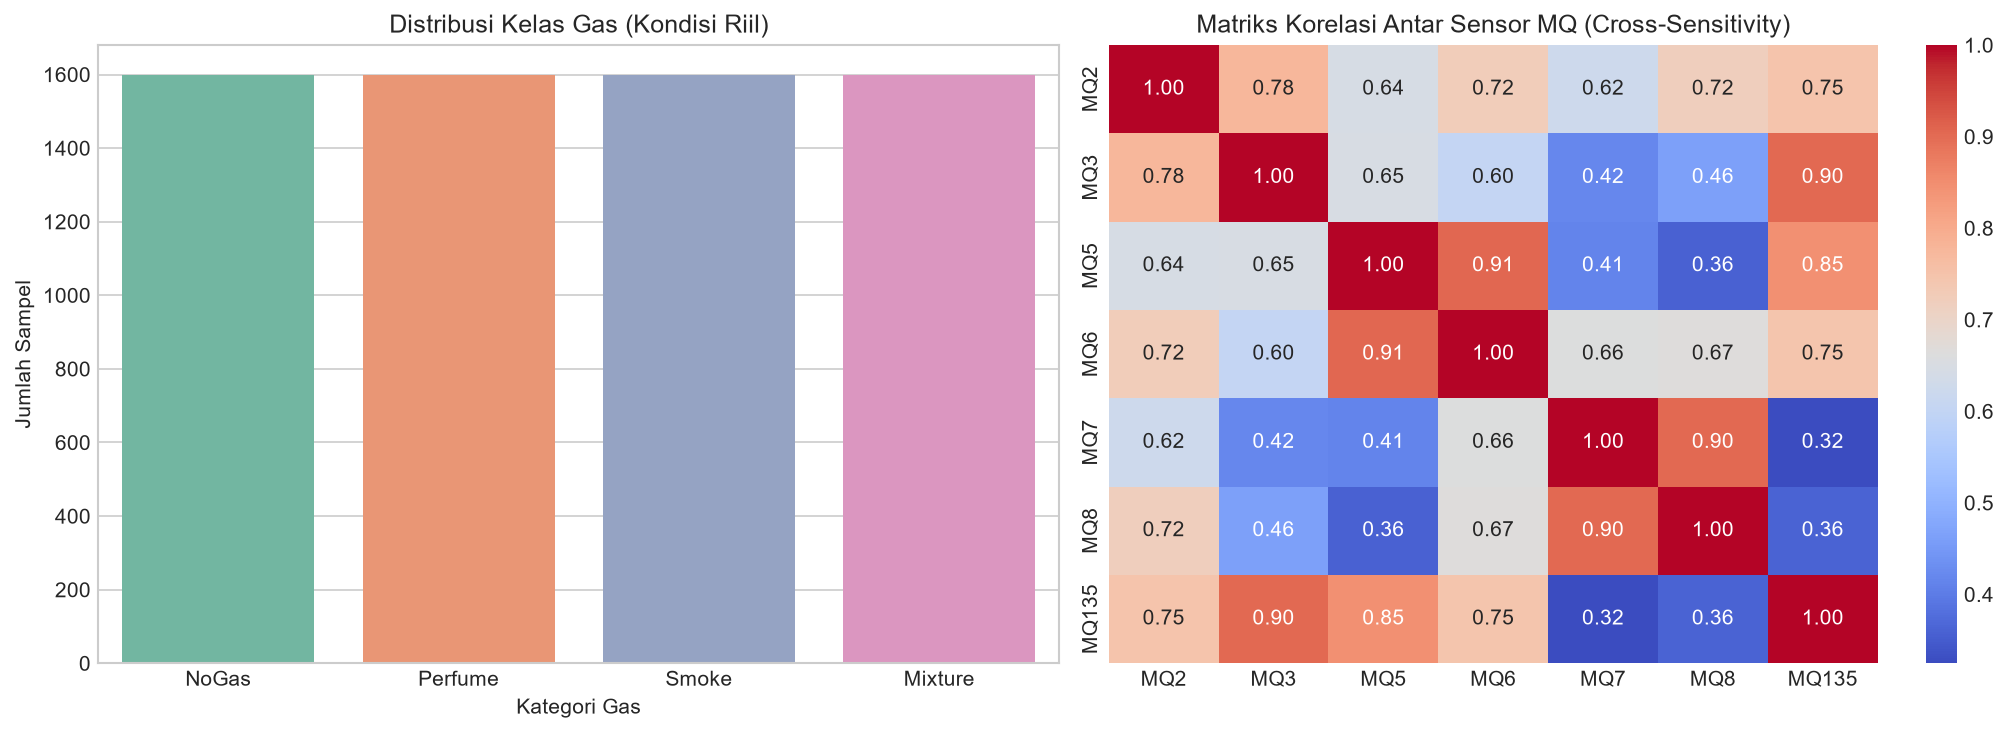

In [3]:
print("=== 2. EKSPLORASI DATA & KORELASI ANTAR SENSOR MQ ===")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi Target
sns.countplot(data=df, x='Gas', hue='Gas', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribusi Kelas Gas (Kondisi Riil)')
axes[0].set_xlabel('Kategori Gas')
axes[0].set_ylabel('Jumlah Sampel')

# Heatmap Korelasi
sensor_cols = ['MQ2', 'MQ3', 'MQ5', 'MQ6', 'MQ7', 'MQ8', 'MQ135']
corr = df[sensor_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Matriks Korelasi Antar Sensor MQ (Cross-Sensitivity)')

plt.tight_layout()
plt.savefig('grafik_korelasi_sensor.png', dpi=150)
plt.show()

=== 3. EKSPERIMEN PENGARUH HYPERPARAMETER (KURVA SENSITIVITAS) ===


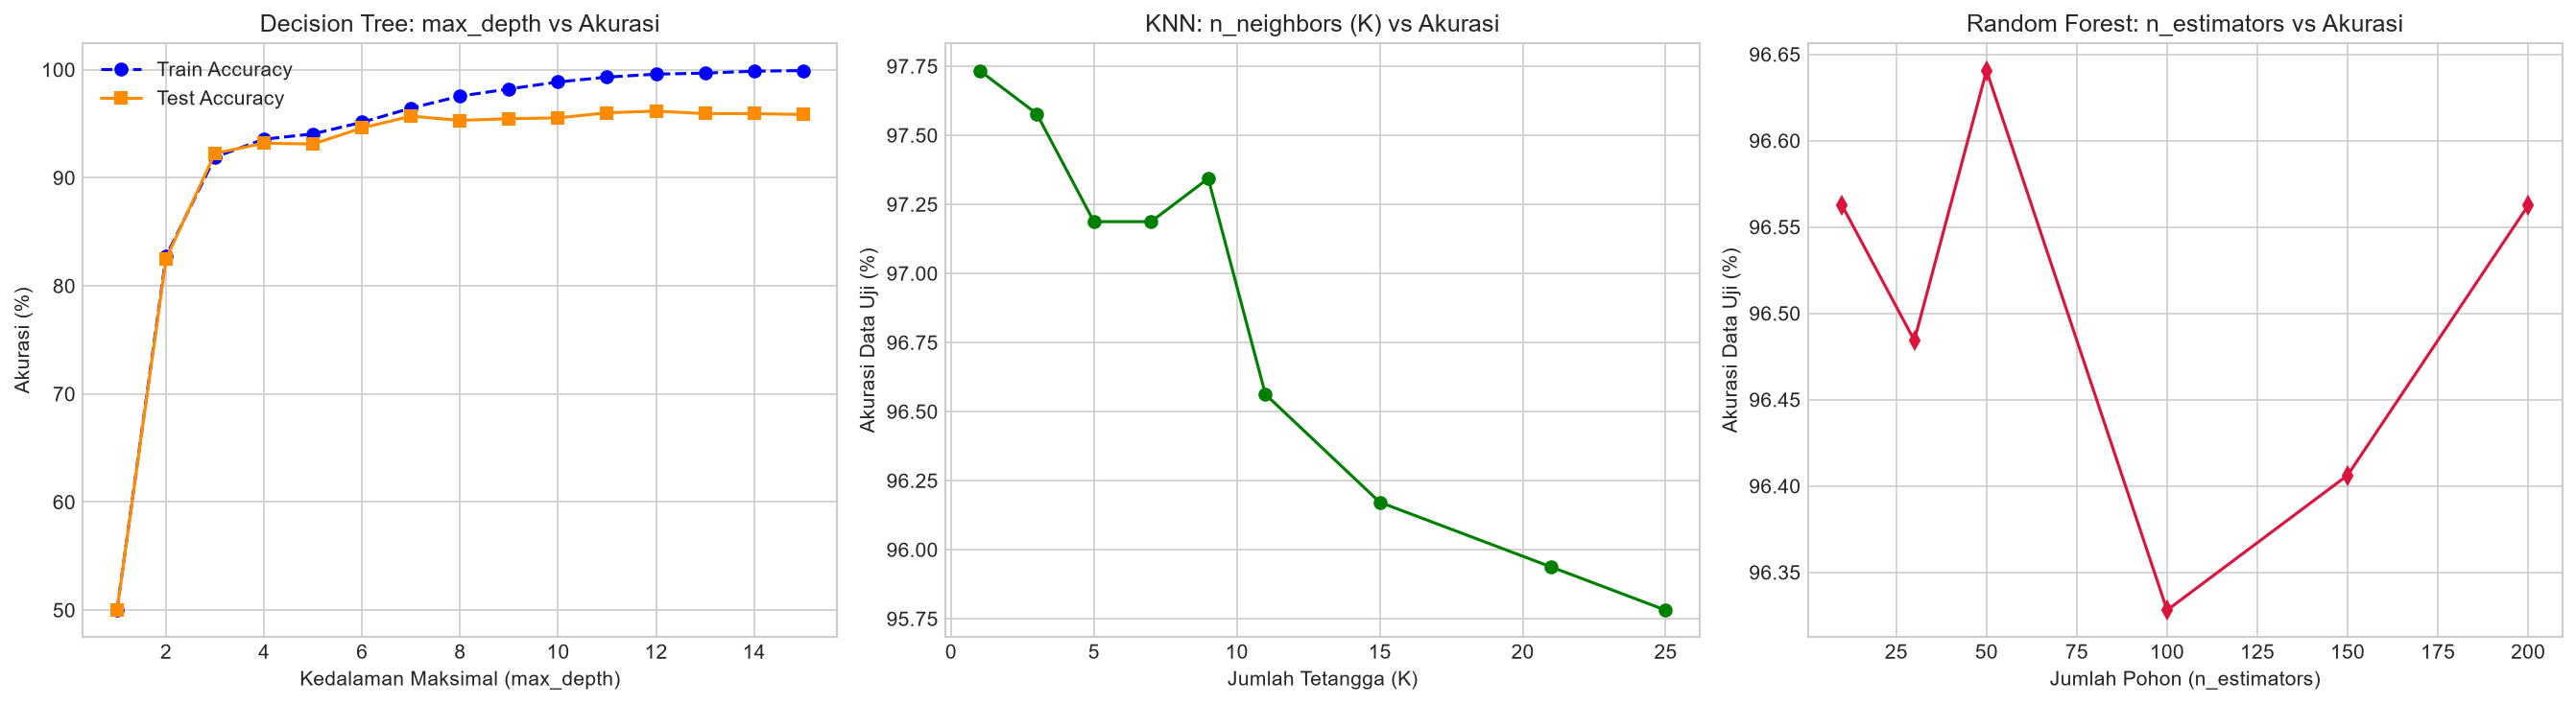

In [4]:
print("=== 3. EKSPERIMEN PENGARUH HYPERPARAMETER (KURVA SENSITIVITAS) ===")
# Menggunakan Full Sensor Array
X_full = df[sensor_cols]
y_target = df['Gas']
X_tr, X_ts, y_tr, y_ts = train_test_split(X_full, y_target, test_size=0.2, random_state=42, stratify=y_target)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_ts_sc = scaler.transform(X_ts)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Decision Tree: Pengaruh max_depth (Underfitting vs Overfitting)
depths = range(1, 16)
dt_train_acc, dt_test_acc = [], []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_tr, y_tr)
    dt_train_acc.append(accuracy_score(y_tr, clf.predict(X_tr)) * 100)
    dt_test_acc.append(accuracy_score(y_ts, clf.predict(X_ts)) * 100)

axes[0].plot(depths, dt_train_acc, 'o--', color='blue', label='Train Accuracy')
axes[0].plot(depths, dt_test_acc, 's-', color='darkorange', label='Test Accuracy')
axes[0].set_title('Decision Tree: max_depth vs Akurasi')
axes[0].set_xlabel('Kedalaman Maksimal (max_depth)')
axes[0].set_ylabel('Akurasi (%)')
axes[0].legend()

# 2. KNN: Pengaruh nilai K (n_neighbors)
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 25]
knn_acc = []
for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_tr_sc, y_tr)
    knn_acc.append(accuracy_score(y_ts, clf.predict(X_ts_sc)) * 100)

axes[1].plot(k_values, knn_acc, 'o-', color='green')
axes[1].set_title('KNN: n_neighbors (K) vs Akurasi')
axes[1].set_xlabel('Jumlah Tetangga (K)')
axes[1].set_ylabel('Akurasi Data Uji (%)')

# 3. Random Forest: Pengaruh n_estimators (Jumlah Pohon)
estimators = [10, 30, 50, 100, 150, 200]
rf_acc = []
for n in estimators:
    clf = RandomForestClassifier(n_estimators=n, max_depth=8, random_state=42, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    rf_acc.append(accuracy_score(y_ts, clf.predict(X_ts)) * 100)

axes[2].plot(estimators, rf_acc, 'd-', color='crimson')
axes[2].set_title('Random Forest: n_estimators vs Akurasi')
axes[2].set_xlabel('Jumlah Pohon (n_estimators)')
axes[2].set_ylabel('Akurasi Data Uji (%)')

plt.tight_layout()
plt.savefig('grafik_variasi_hyperparameter.png', dpi=150)
plt.show()

In [5]:
print("=== 4. HYPERPARAMETER TUNING SISTEMATIS (GRIDSEARCHCV) ===")

# Tuning Decision Tree
dt_params = {'max_depth': [3, 5, 8, 12, None], 'criterion': ['gini', 'entropy'], 'min_samples_split': [2, 5, 10]}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_params, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid.fit(X_tr, y_tr)
best_dt = dt_grid.best_estimator_

# Tuning KNN
knn_params = {'n_neighbors': [1, 3, 5, 7, 9, 15], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='accuracy', n_jobs=-1)
knn_grid.fit(X_tr_sc, y_tr)
best_knn = knn_grid.best_estimator_

# Tuning Random Forest
rf_params = {'n_estimators': [50, 100, 200], 'max_depth': [5, 8, 12, None], 'criterion': ['gini', 'entropy']}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_tr, y_tr)
best_rf = rf_grid.best_estimator_

print("Hyperparameter Terbaik yang Ditemukan:")
print(" - Decision Tree :", dt_grid.best_params_)
print(" - KNN           :", knn_grid.best_params_)
print(" - Random Forest :", rf_grid.best_params_)

=== 4. HYPERPARAMETER TUNING SISTEMATIS (GRIDSEARCHCV) ===
Hyperparameter Terbaik yang Ditemukan:
 - Decision Tree : {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5}
 - KNN           : {'metric': 'manhattan', 'n_neighbors': 1, 'weights': 'uniform'}
 - Random Forest : {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 200}


In [6]:
print("=== 5. EVALUASI MODEL SETELAH TUNING (CLASSIFICATION REPORT) ===")

y_pred_dt = best_dt.predict(X_ts)
y_pred_knn = best_knn.predict(X_ts_sc)
y_pred_rf = best_rf.predict(X_ts)

print("Akurasi Evaluasi Data Uji (1.280 Sampel):")
print(f" -> Decision Tree : {accuracy_score(y_ts, y_pred_dt)*100:.2f}% | F1: {f1_score(y_ts, y_pred_dt, average='weighted')*100:.2f}%")
print(f" -> KNN           : {accuracy_score(y_ts, y_pred_knn)*100:.2f}% | F1: {f1_score(y_ts, y_pred_knn, average='weighted')*100:.2f}%")
print(f" -> Random Forest : {accuracy_score(y_ts, y_pred_rf)*100:.2f}% | F1: {f1_score(y_ts, y_pred_rf, average='weighted')*100:.2f}%")

print("\n" + "="*50)
print("CLASSIFICATION REPORT - RANDOM FOREST (MODEL TERBAIK):")
print("="*50)
print(classification_report(y_ts, y_pred_rf))

=== 5. EVALUASI MODEL SETELAH TUNING (CLASSIFICATION REPORT) ===
Akurasi Evaluasi Data Uji (1.280 Sampel):
 -> Decision Tree : 96.48% | F1: 96.48%
 -> KNN           : 97.73% | F1: 97.73%
 -> Random Forest : 97.81% | F1: 97.81%

CLASSIFICATION REPORT - RANDOM FOREST (MODEL TERBAIK):
              precision    recall  f1-score   support

     Mixture       1.00      1.00      1.00       320
       NoGas       0.95      0.96      0.96       320
     Perfume       0.96      0.95      0.96       320
       Smoke       1.00      1.00      1.00       320

    accuracy                           0.98      1280
   macro avg       0.98      0.98      0.98      1280
weighted avg       0.98      0.98      0.98      1280


=== 6. VISUALISASI CONFUSION MATRIX KOMPARATIF ===


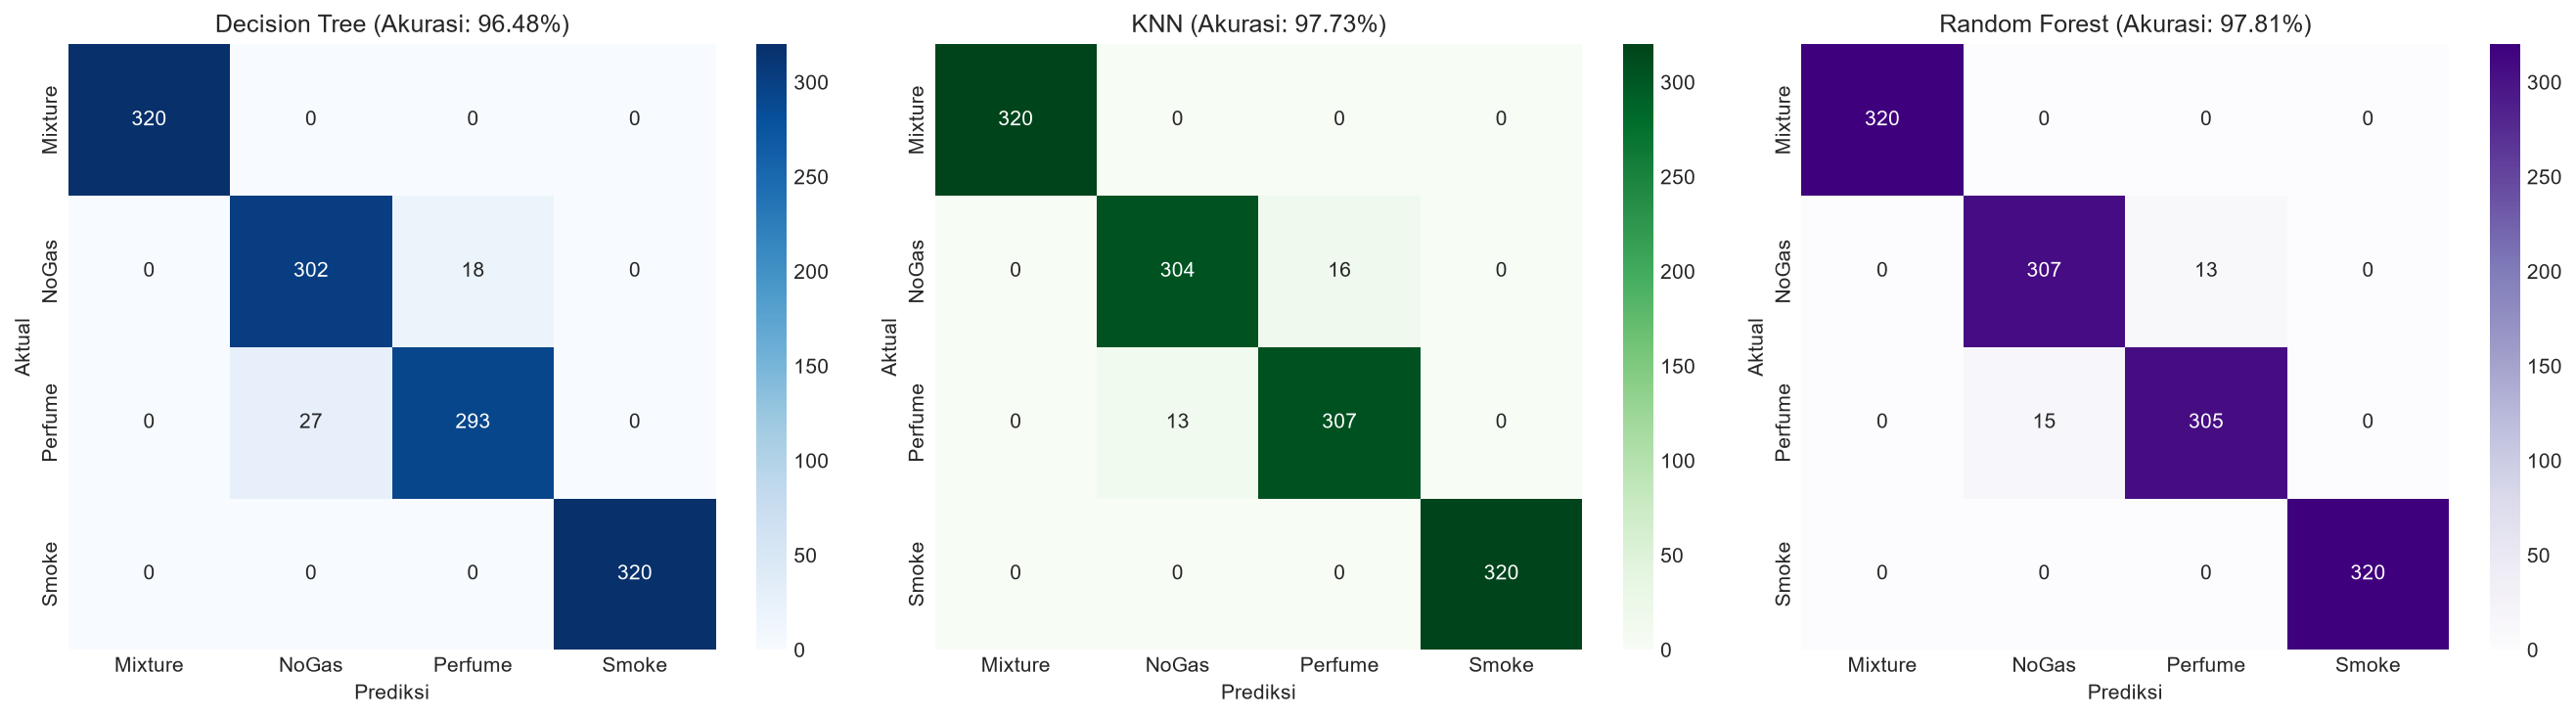

In [7]:
print("=== 6. VISUALISASI CONFUSION MATRIX KOMPARATIF ===")
classes = sorted(list(y_target.unique()))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# DT
cm_dt = confusion_matrix(y_ts, y_pred_dt, labels=classes)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=classes, yticklabels=classes)
axes[0].set_title(f'Decision Tree (Akurasi: {accuracy_score(y_ts, y_pred_dt)*100:.2f}%)')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# KNN
cm_knn = confusion_matrix(y_ts, y_pred_knn, labels=classes)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1], xticklabels=classes, yticklabels=classes)
axes[1].set_title(f'KNN (Akurasi: {accuracy_score(y_ts, y_pred_knn)*100:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

# RF
cm_rf = confusion_matrix(y_ts, y_pred_rf, labels=classes)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples', ax=axes[2], xticklabels=classes, yticklabels=classes)
axes[2].set_title(f'Random Forest (Akurasi: {accuracy_score(y_ts, y_pred_rf)*100:.2f}%)')
axes[2].set_xlabel('Prediksi')
axes[2].set_ylabel('Aktual')

plt.tight_layout()
plt.savefig('confusion_matrix_komparatif_3_model.png', dpi=150)
plt.show()

=== 7. ANALISIS TINGKAT KEPENTINGAN FITUR SENSOR (FEATURE IMPORTANCE) ===
Kontribusi sensor paling dominan:
MQ3      0.273662
MQ8      0.194415
MQ135    0.176057
MQ7      0.126195
MQ2      0.088927
MQ5      0.079661
MQ6      0.061082
dtype: float64


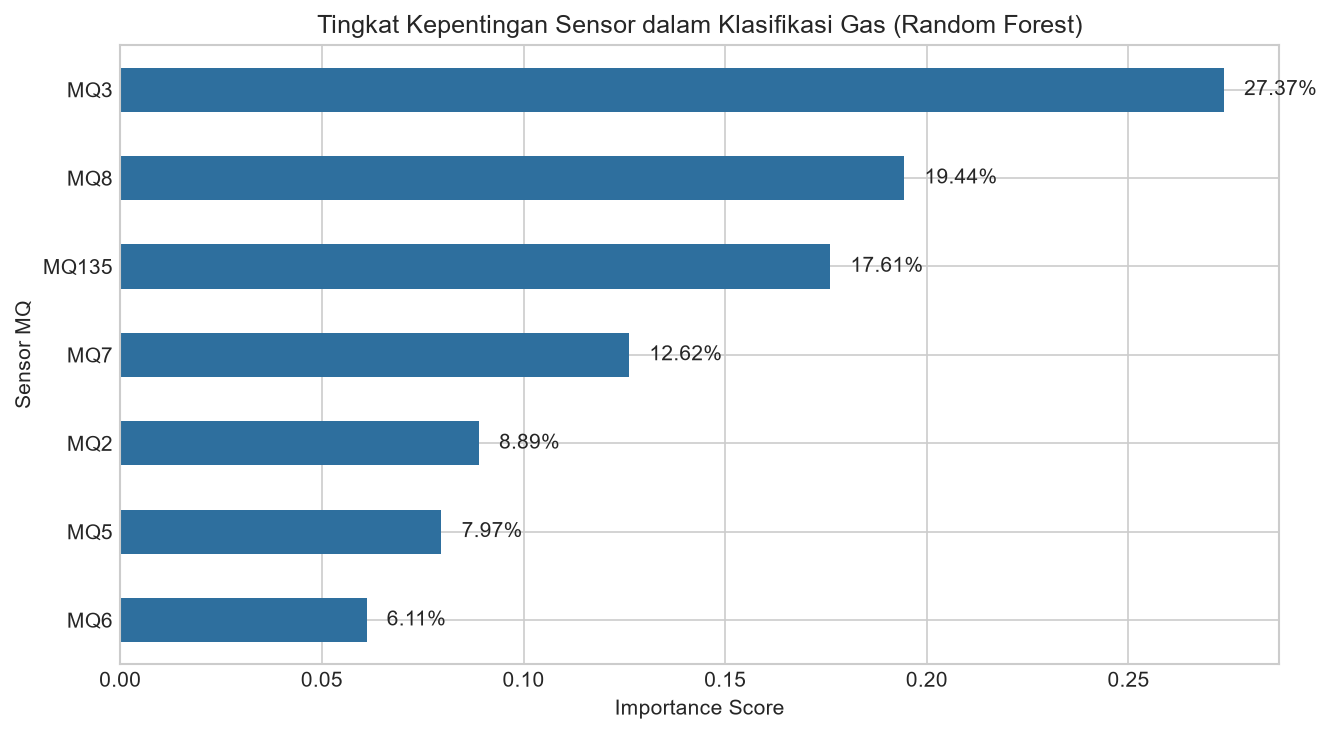

In [8]:
print("=== 7. ANALISIS TINGKAT KEPENTINGAN FITUR SENSOR (FEATURE IMPORTANCE) ===")
feat_imp = pd.Series(best_rf.feature_importances_, index=sensor_cols).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
feat_imp.plot(kind='barh', color='#2e6f9e')
plt.title('Tingkat Kepentingan Sensor dalam Klasifikasi Gas (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Sensor MQ')

for index, value in enumerate(feat_imp):
    plt.text(value + 0.005, index, f"{value*100:.2f}%", va='center')

plt.tight_layout()
plt.savefig('feature_importance_enose.png', dpi=150)
plt.show()
print("Kontribusi sensor paling dominan:")
print(feat_imp.sort_values(ascending=False))

=== 8. KOMPARASI LINTAS SKENARIO FITUR SENSOR (SINGLE SENSOR VS E-NOSE) ===
               Skenario Fitur  Jumlah Sensor  Decision Tree (%)  KNN (%)  Random Forest (%)
       Skenario 1 (MQ-2 Saja)              1              58.20    57.89              57.27
   Skenario 2 (MQ-2 + MQ-135)              2              84.06    85.31              85.94
Skenario 3 (Full 7 Sensor MQ)              7              96.48    97.73              97.81


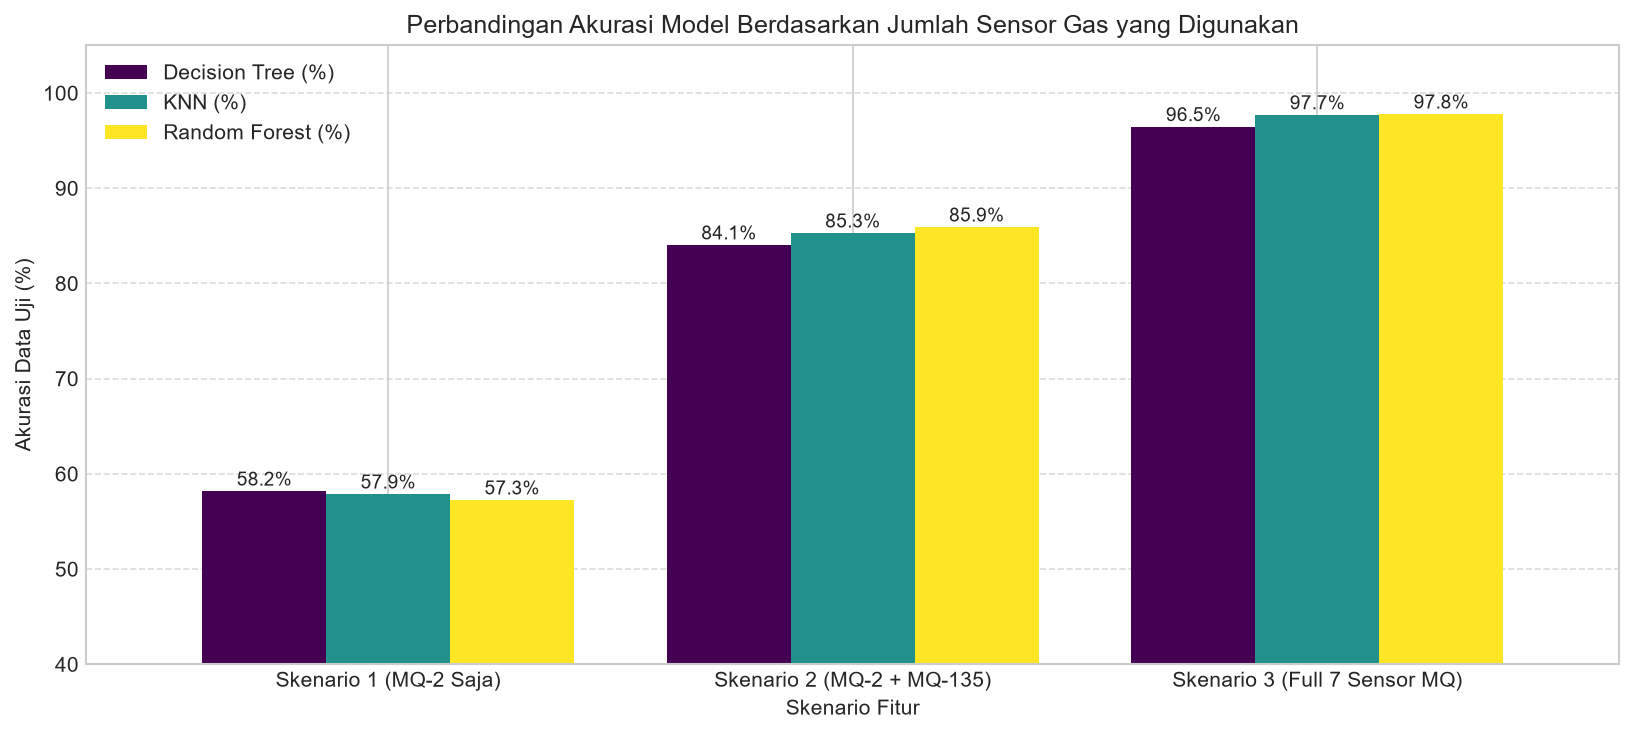

In [9]:
print("=== 8. KOMPARASI LINTAS SKENARIO FITUR SENSOR (SINGLE SENSOR VS E-NOSE) ===")
# Data rekapitulasi performa lintas skenario sensor
scenarios_summary = pd.DataFrame({
    'Skenario Fitur': [
        'Skenario 1 (MQ-2 Saja)',
        'Skenario 2 (MQ-2 + MQ-135)',
        'Skenario 3 (Full 7 Sensor MQ)'
    ],
    'Jumlah Sensor': [1, 2, 7],
    'Decision Tree (%)': [58.20, 84.06, 96.48],
    'KNN (%)': [57.89, 85.31, 97.73],
    'Random Forest (%)': [57.27, 85.94, 97.81]
})

print(scenarios_summary.to_string(index=False))

# Plot Komparasi Lintas Skenario
scenarios_plot = scenarios_summary.set_index('Skenario Fitur')[['Decision Tree (%)', 'KNN (%)', 'Random Forest (%)']]
ax = scenarios_plot.plot(kind='bar', figsize=(11, 5), colormap='viridis', width=0.8)
plt.title('Perbandingan Akurasi Model Berdasarkan Jumlah Sensor Gas yang Digunakan')
plt.ylabel('Akurasi Data Uji (%)')
plt.ylim(40, 105)
plt.xticks(rotation=0)
plt.legend(loc='upper left', framealpha=0.9, shadow=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.savefig('grafik_komparasi_skenario_sensor.png', dpi=150)
plt.show()

In [10]:
print("=== 9. EKSPOR ARTEFAK MODEL & PIPELINE INFERENSI REAL-TIME ===")
joblib.dump(best_rf, 'best_random_forest.joblib')
joblib.dump(best_dt, 'best_decision_tree.joblib')
joblib.dump(best_knn, 'best_knn.joblib')
joblib.dump(scaler, 'scaler_enose.joblib')
print("Model berhasil disimpan: best_random_forest.joblib, best_decision_tree.joblib, scaler_enose.joblib")

def predict_gas_condition(mq_readings_dict, model_choice='rf'):
    """
    Fungsi inferensi untuk memprediksi jenis gas dari data pembacaan sensor MQ.
    
    Parameters:
        mq_readings_dict (dict): Dictionary nilai 7 sensor MQ {'MQ2': val, ..., 'MQ135': val}
        model_choice (str): 'rf' (Random Forest), 'dt' (Decision Tree), 'knn' (KNN)
    """
    cols = ['MQ2', 'MQ3', 'MQ5', 'MQ6', 'MQ7', 'MQ8', 'MQ135']
    input_data = pd.DataFrame([[mq_readings_dict[c] for c in cols]], columns=cols)
    
    if model_choice.lower() == 'knn':
        input_scaled = scaler.transform(input_data)
        pred = best_knn.predict(input_scaled)[0]
        conf = np.max(best_knn.predict_proba(input_scaled)) * 100
    elif model_choice.lower() == 'dt':
        pred = best_dt.predict(input_data)[0]
        conf = np.max(best_dt.predict_proba(input_data)) * 100
    else:
        pred = best_rf.predict(input_data)[0]
        conf = np.max(best_rf.predict_proba(input_data)) * 100
        
    saran = {
        'NoGas': 'Kondisi udara normal dan aman. Tidak ada gas berbahaya terdeteksi.',
        'Smoke': 'PERINGATAN: Terdeteksi konsentrasi asap pembakaran! Waspada potensi kebakaran.',
        'Perfume': 'Terdeteksi uap senyawa volatil / alkohol (parfum atau pembersih ruangan).',
        'Mixture': 'Terdeteksi campuran gas reaktif. Segera pastikan ventilasi ruangan terbuka.'
    }
    
    return {
        'Prediksi Gas': pred,
        'Keyakinan (Confidence)': f"{conf:.2f}%",
        'Model Digunakan': 'Random Forest' if model_choice.lower() == 'rf' else ('KNN' if model_choice.lower() == 'knn' else 'Decision Tree'),
        'Rekomendasi': saran.get(pred, '-')
    }

# Uji Coba Sampel Nyata
sample_test = {'MQ2': 780, 'MQ3': 510, 'MQ5': 690, 'MQ6': 650, 'MQ7': 680, 'MQ8': 770, 'MQ135': 540}
hasil = predict_gas_condition(sample_test, model_choice='rf')
print("\nHasil Uji Coba Fungsi Inferensi:")
print("Input Pembacaan Sensor:", sample_test)
print(f" -> Status: [{hasil['Prediksi Gas']}] (Confidence: {hasil['Keyakinan (Confidence)']})")
print(f" -> Saran : {hasil['Rekomendasi']}")

=== 9. EKSPOR ARTEFAK MODEL & PIPELINE INFERENSI REAL-TIME ===
Model berhasil disimpan: best_random_forest.joblib, best_decision_tree.joblib, scaler_enose.joblib

Hasil Uji Coba Fungsi Inferensi:
Input Pembacaan Sensor: {'MQ2': 780, 'MQ3': 510, 'MQ5': 690, 'MQ6': 650, 'MQ7': 680, 'MQ8': 770, 'MQ135': 540}
 -> Status: [Perfume] (Confidence: 94.00%)
 -> Saran : Terdeteksi uap senyawa volatil / alkohol (parfum atau pembersih ruangan).
